<a href="https://colab.research.google.com/github/yogfity/nvax-stock-return-analysis/blob/main/nvax_stock_return_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Python Excercise 1, Task 2: Stock Calculations and more - Oliver Hall - zum23

**Key findings: Novavax (NVAX), Jan 2017 to Dec 2023**

* \$100 invested in January 2017 grew to about **\$1,260** at the early 2021 peak, then fell to about **\$19** by the end of 2023.
* The worst day was Feb 28, 2019 (**-66.7%**), when Novavax's RSV vaccine failed its Phase 3 trial. The best day was Jan 21, 2020 (**+71.1%**), on early COVID vaccine news.
* Daily volatility was **7.27%** (about **115%** annualized), about 6 times the S&P 500. NVAX moved 10% or more in a single day **163 times**.
* The average day was slightly positive (+0.17%), yet the investment lost about 80%. Big swings drag down compounded returns, a concept called volatility drag. The stock only rose on 45% of days.
* Returns have **fat tails** (kurtosis of 20.6, vs 0 for a normal bell curve), so a bell curve risk model would badly understate how often extreme days happen.

*Tools: Python (pandas, yfinance, matplotlib, seaborn), Google Colab*

***1) Install yfinance:***

In [13]:
!pip install yfinance


***2) Import the modules:***

In [14]:
import yfinance as yf
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
%config InlineBackend.figure_format = 'svg'

***3) Download NVAX prices:***

In [15]:
dataset = yf.download("NVAX", start="2017-01-01", end="2023-12-31",
                      auto_adjust=False, multi_level_index=False)
dataset

[*********************100%***********************]  1 of 1 completed


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2017-01-03,25.400000,25.400000,26.400000,24.000000,25.600000,414510
2017-01-04,26.200001,26.200001,26.400000,25.400000,25.600000,323810
2017-01-05,26.400000,26.400000,26.799999,26.000000,26.799999,263595
2017-01-06,27.400000,27.400000,27.799999,26.400000,26.400000,309010
2017-01-09,28.400000,28.400000,29.000000,27.200001,27.799999,394160
...,...,...,...,...,...,...
2023-12-22,5.060000,5.060000,5.170000,4.900000,4.940000,7924800
2023-12-26,5.050000,5.050000,5.190000,5.030000,5.150000,4775900
2023-12-27,4.940000,4.940000,5.080000,4.890000,5.020000,8607300


***4) What $100 invested in January 2017 turned into:***

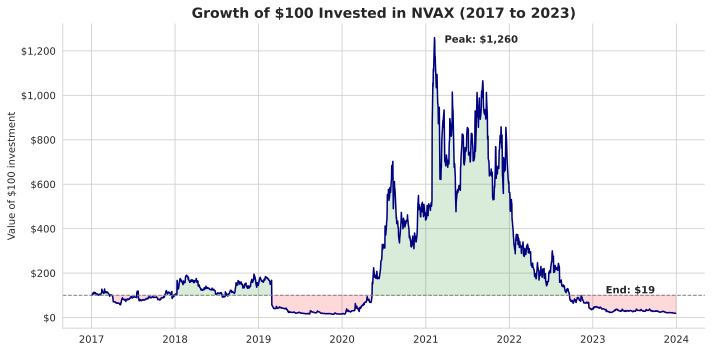

In [16]:
growth = dataset['Adj Close'] / dataset['Adj Close'].iloc[0] * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(growth, color='navy', linewidth=1.5)
ax.axhline(100, color='gray', linestyle='--', linewidth=1)
ax.fill_between(growth.index, growth, 100, where=(growth >= 100), color='green', alpha=0.15, interpolate=True)
ax.fill_between(growth.index, growth, 100, where=(growth < 100), color='red', alpha=0.15, interpolate=True)

peak_date = growth.idxmax()
peak_val = growth.max()
end_val = growth.iloc[-1]
ax.annotate(f'Peak: ${peak_val:,.0f}', xy=(peak_date, peak_val), xytext=(10, -5), textcoords='offset points', fontweight='bold')
ax.annotate(f'End: ${end_val:,.0f}', xy=(growth.index[-1], end_val), xytext=(-70, 20), textcoords='offset points', fontweight='bold')

ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Growth of $100 Invested in NVAX (2017 to 2023)', fontsize=14, fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Value of $100 investment')
sns.despine()
plt.tight_layout()
plt.show()

***5) Daily returns:***

In [17]:
ret = dataset['Adj Close'].pct_change().dropna()
ret.describe()


,Adj Close
count,1759.000000
mean,0.001652
std,0.072701
min,-0.666667
25%,-0.032286
50%,-0.002494
75%,0.028125
max,0.710801


In [18]:
print('Worst day:', ret.idxmin().date(), round(ret.min() * 100, 1), '%')
print('Best day:', ret.idxmax().date(), round(ret.max() * 100, 1), '%')

Worst day: 2019-02-28 -66.7 %
Best day: 2020-01-21 71.1 %


***6) Plot the Returns***

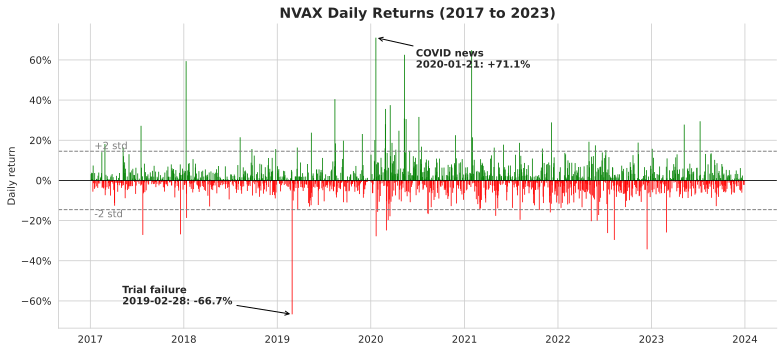

In [19]:
colors = ['green' if r > 0 else 'red' for r in ret]
std = ret.std()

fig, ax = plt.subplots(figsize=(11, 5))
ax.vlines(ret.index, 0, ret, colors=colors, linewidth=0.8)
ax.axhline(0, color='black', linewidth=0.8)
ax.axhline(2 * std, color='gray', linestyle='--', linewidth=1)
ax.axhline(-2 * std, color='gray', linestyle='--', linewidth=1)
ax.text(ret.index[0], 2 * std, ' +2 std', va='bottom', color='gray')
ax.text(ret.index[0], -2 * std, ' -2 std', va='top', color='gray')

worst_date, worst = ret.idxmin(), ret.min()
best_date, best = ret.idxmax(), ret.max()
ax.annotate(f'Trial failure\n{worst_date.date()}: {worst:.1%}', xy=(worst_date, worst),
            xytext=(-170, 10), textcoords='offset points', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='black'))
ax.annotate(f'COVID news\n{best_date.date()}: +{best:.1%}', xy=(best_date, best),
            xytext=(40, -30), textcoords='offset points', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='black'))

ax.yaxis.set_major_formatter('{x:.0%}')
ax.set_title('NVAX Daily Returns (2017 to 2023)', fontsize=14, fontweight='bold')
ax.set_ylabel('Daily return')
sns.despine()
plt.tight_layout()
plt.show()

***7) Histogram of Returns***

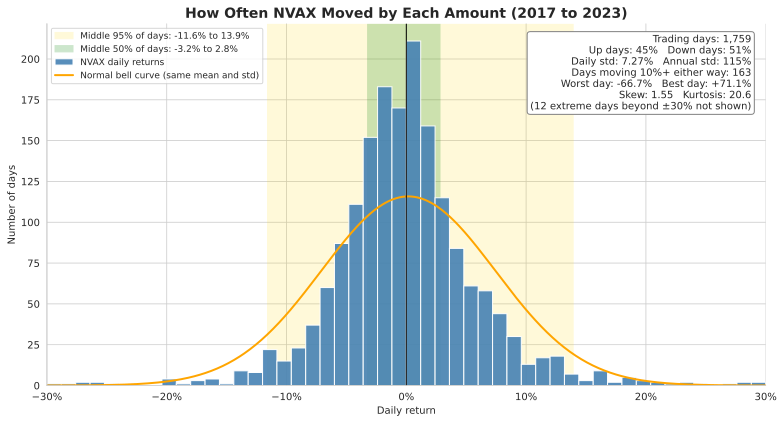

In [20]:
mean, std = ret.mean(), ret.std()
lo50, hi50 = ret.quantile(0.25), ret.quantile(0.75)
lo95, hi95 = ret.quantile(0.025), ret.quantile(0.975)
limit = 0.30
bins = np.linspace(-limit, limit, 51)
bin_width = bins[1] - bins[0]
off_chart = (ret.abs() > limit).sum()

x = np.linspace(-limit, limit, 500)
normal_curve = np.exp(-0.5 * ((x - mean) / std) ** 2) / (std * np.sqrt(2 * np.pi)) * len(ret) * bin_width

fig, ax = plt.subplots(figsize=(11, 6))
ax.axvspan(lo95, hi95, color='gold', alpha=0.15, label=f'Middle 95% of days: {lo95:.1%} to {hi95:.1%}')
ax.axvspan(lo50, hi50, color='green', alpha=0.2, label=f'Middle 50% of days: {lo50:.1%} to {hi50:.1%}')
ax.hist(ret, bins=bins, alpha=0.9, color='steelblue', edgecolor='white', label='NVAX daily returns')
ax.plot(x, normal_curve, color='orange', linewidth=2, label='Normal bell curve (same mean and std)')
ax.axvline(0, color='black', linewidth=1)

stats_text = (f'Trading days: {len(ret):,}\n'
              f'Up days: {(ret > 0).mean():.0%}   Down days: {(ret < 0).mean():.0%}\n'
              f'Daily std: {std:.2%}   Annual std: {std * np.sqrt(252):.0%}\n'
              f'Days moving 10%+ either way: {(ret.abs() >= 0.10).sum()}\n'
              f'Worst day: {ret.min():.1%}   Best day: {ret.max():+.1%}\n'
              f'Skew: {ret.skew():.2f}   Kurtosis: {ret.kurt():.1f}\n'
              f'({off_chart} extreme days beyond ±{limit:.0%} not shown)')
ax.text(0.98, 0.97, stats_text, transform=ax.transAxes, ha='right', va='top', fontsize=10,
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray'))

ax.set_xlim(-limit, limit)
ax.xaxis.set_major_formatter('{x:.0%}')
ax.set_title('How Often NVAX Moved by Each Amount (2017 to 2023)', fontsize=14, fontweight='bold')
ax.set_xlabel('Daily return')
ax.set_ylabel('Number of days')
ax.legend(loc='upper left', fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()